# Goal Room DQN

Train a deep Q network to reach the Woodsman's Hut.

This notebook uses NumPy clones of some bits of PyTorch in the [`numpy_torch`](numpy_torch.py) module alongside this file so that it can run in WebAssembly. It copies the PyTorch API, so with PyTorch installed you can swap the import below to use it instead. The live views under the training cell come from [`display`](display.py), so if you download this notebook, download both modules too.

In [1]:
# before numpy_torch, since the browser only loads the packages a cell imports
import numpy as np
import numpy_torch as torch  # swap this to `import torch` to use PyTorch

## Settings

In [2]:
goal_room = "woodsman's hut"  # the goal room name we're trying to reach
training_episodes = 1000
max_episode_steps = 50
eval_interval = 10  # run our evals each time we've completed this many episodes
eval_episodes = 5  # run this many eval episodes, and stop training the first time all of these reach the goal
learning_rate = 0.001  # how quickly we move the weights
discount = 0.95  # γ / gamma, each step away from the reward scales by this amount
seed = None  # set to make reproducible or leave as None for random seeds each time

In [3]:
from copy import deepcopy
from time import perf_counter

import gymnasium as gym

# display.py draws with matplotlib, and the browser only loads the packages a cell imports
import matplotlib  # noqa: F401
from display import LearningCurves, Screen
from IPython.display import HTML, display

from mudgym import make_env
from mudgym.notebooks import show_ansi, show_episode_transcript, show_space, show_table

## Environment

We're using MudGym's `cheats` observation mode, which gives us the current room's index as `room_id_index` and available directions as `available_exits`. For the action space we're using `directions` which gives us a smaller discrete action space of the 14 movement directions.

In [4]:
env = make_env(observation="cheats", actions="directions")

In [5]:
show_space(env.observation_space)

asleep,"Discrete(2, dtype=int8)"
available_exit_names,Sequence(Text(max_length=9))
available_exits,MultiBinary(14)
dark,"Discrete(2, dtype=int8)"
fighting,"Discrete(2, dtype=int8)"
flags,MultiBinary(4)
gifted,"Discrete(2, dtype=int8)"
glowing,"Discrete(2, dtype=int8)"
here,Sequence(Text(max_length=96))
inventory,Sequence(Text(max_length=17))
points,"Box(0, 204800, (), int32)"


In [6]:
commands = env.commands
print(env.action_space)
show_table(
    [{"Action": action, "Command": command} for action, command in enumerate(commands)],
    mono_columns=("Command",),
)

Discrete(14)


0,move north
1,move east
2,move south
3,move west
4,move northeast
5,move southeast
6,move southwest
7,move northwest
8,move up
9,move down
10,move in


We use a wrapper to modify the env to reward the agent for reaching our desired goal room with a reward of +1 and we ignore the usual rewards from the game. We also add a small negative step penalty reward of -0.01 for all other steps to encourage shorter routes to the goal. Reaching the goal ends the episode.

In [7]:
class GoalRoomReward(gym.Wrapper):
    def __init__(self, env, goal_room, success_reward=1.0, step_penalty=-0.01):
        super().__init__(env)
        self.goal_room = goal_room
        self.success_reward = success_reward
        self.step_penalty = step_penalty

    def step(self, action):
        observation, _, terminated, truncated, info = self.env.step(action)
        success = observation["room_name"] == self.goal_room
        reward = self.success_reward if success else self.step_penalty
        info = {**info, "is_success": success}
        return observation, reward, terminated or success, truncated, info


# wrap our env
env = GoalRoomReward(env, goal_room=goal_room)

# a separate eval env, so its seeded resets don't change the worlds training plays
eval_env = GoalRoomReward(make_env(observation="cheats", actions="directions"), goal_room=goal_room)

In [8]:
# call reset to start an episode and have a look where we start
sample_observation, sample_info = env.reset()
display(show_ansi(sample_info["render_bytes"]))
print("Room ID:", sample_observation["room_id"])
print("Room ID index:", sample_observation["room_id_index"])
print("Available exits:", ", ".join(sample_observation["available_exit_names"]))

<HTML output, 1128 characters>

Room ID: mstart
Room ID index: 653
Available exits: north, east, south, west, northeast, southeast, southwest, northwest, up, out, swampward


## Model

The network we will train takes a room ID index number as input and returns a Q value for each movement direction, its estimate of the discounted reward to come if we go that way. It only sees the room, and we use the available exits to rule out moves we can't make, both when picking an action and when working out targets.

We look up the room in an embedding layer, then pass the output through two linear + ReLU layers, followed by a final linear layer outputting a Q value per direction.

```text
room
  |
  v
embedding        a 64 dim embedding representing this room
  |
  v
linear + ReLU    64 -> 64
  |
  v
linear + ReLU    64 -> 64
  |
  v
linear           64 -> 14
  |
  v
Q values         one per direction
```

In [9]:
class QNetwork(torch.nn.Module):
    """A room embedding -> two ReLU hidden layers -> linear Q value head."""

    def __init__(self, room_count: int, action_count: int, *, embedding_dim: int = 64, hidden_dim: int = 64) -> None:
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Embedding(room_count, embedding_dim),
            torch.nn.Linear(embedding_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, action_count),
        )

    def forward(self, room_indices):
        """Q values with shape (B, A) for a batch of B room indices."""
        return self.layers(room_indices)

## Replay and targets

Every training move goes into a replay buffer, and the network learns from random batches of these transitions.

In [10]:
class ReplayBuffer:
    def __init__(self, capacity: int, action_count: int) -> None:
        self.capacity = capacity
        self.size = 0
        self.position = 0
        self.columns = (
            np.empty(capacity, dtype=np.int64),  # state
            np.empty(capacity, dtype=np.int64),  # action
            np.empty(capacity, dtype=np.float32),  # reward
            np.empty(capacity, dtype=np.int64),  # next state
            np.empty((capacity, action_count), dtype=np.bool_),  # next exits
            np.empty(capacity, dtype=np.bool_),  # terminated, not truncated
        )

    def __len__(self) -> int:
        return self.size

    def add(self, state, action, reward, next_state, next_mask, terminated) -> None:
        for column, value in zip(self.columns, (state, action, reward, next_state, next_mask, terminated), strict=True):
            column[self.position] = value
        self.position = (self.position + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size: int, rng: np.random.Generator):
        indices = rng.choice(self.size, batch_size, replace=False)
        return tuple(torch.as_tensor(column[indices]) for column in self.columns)

The `bellman_targets` are what the data in this batch of steps tells us the Q values should have been, ie, the reward achieved, plus a discounted estimate of the best we can do from the next room if we act optimally.

We use a second copy of the network for this, the `target_network`, which we update periodically. This makes training more stable, because what we're aiming at doesn't jump around so much with each update of the weights.

In [11]:
def bellman_targets(target_network, rewards, next_states, next_masks, terminated, discount):
    """Reward plus the discounted best Q value from the next room, or just the reward if there's no next move."""
    with torch.no_grad():
        q_next = target_network(next_states)
    best_next = torch.where(next_masks, q_next, -torch.inf).max(dim=1).values
    # only look ahead where there's somewhere to go, so ended episodes never use the -inf
    continuing = ~terminated & next_masks.any(dim=1)
    return rewards + discount * torch.where(continuing, best_next, 0.0)

## Agent

We use an epsilon value to tell the agent to sometimes act randomly. It starts at 1, all random, and we gradually reduce this towards 0.05 as training continues.

Our optimiser, Adam with PyTorch's defaults, nudges each weight in the direction to make the loss lower. It keeps running averages of each gradient and its square, which smooth the steps out.

In [12]:
class DQNAgent:
    """Epsilon-greedy moves, replay updates and a target network."""

    def __init__(
        self,
        room_count: int,
        action_count: int,
        *,
        seed: int | None = None,
        exploration_steps: int = 6_000,
        batch_size: int = 64,
        replay_capacity: int = 20_000,
        learning_starts: int = 128,
        train_every: int = 4,
        target_update_every: int = 20,
        discount: float = 0.95,
        learning_rate: float = 1e-3,
    ) -> None:
        # PyTorch's manual_seed only takes an integer, and without one its generator carries on as it is
        if seed is not None:
            torch.manual_seed(seed)
        self.network = QNetwork(room_count, action_count)
        self.target = deepcopy(self.network)
        self.optimizer = torch.optim.Adam(self.network.parameters(), lr=learning_rate)
        self.replay = ReplayBuffer(replay_capacity, action_count)
        # separate streams, so how often we train doesn't change which random moves we make
        policy_seed, replay_seed = np.random.SeedSequence(seed).spawn(2)
        self.policy_rng = np.random.default_rng(policy_seed)
        self.replay_rng = np.random.default_rng(replay_seed)
        self.action_count = action_count
        self.exploration_steps = exploration_steps
        self.batch_size = batch_size
        self.learning_starts = learning_starts
        self.train_every = train_every
        self.target_update_every = target_update_every
        self.discount = discount
        self.transitions = 0
        self.gradient_steps = 0

    @property
    def epsilon(self) -> float:
        """Falls from 1 to 0.05 over the first exploration_steps moves, then stays there."""
        return max(0.05, 1.0 - 0.95 * self.transitions / self.exploration_steps)

    def q_values(self, state: int) -> np.ndarray:
        """The network's Q value for each direction from one room."""
        with torch.no_grad():
            return self.network(torch.as_tensor([state]))[0].numpy()

    def act(self, state: int, mask, *, explore: bool = True) -> int:
        if explore and self.policy_rng.random() < self.epsilon:
            return int(self.policy_rng.choice(np.flatnonzero(mask)))
        q = self.q_values(state)
        if not np.isfinite(q).all():
            raise FloatingPointError("Training stopped on a non-finite Q value.")
        # best Q value among the available exits
        return int(np.argmax(np.where(mask, q, -np.inf)))

    def observe(self, state, action, reward, next_state, next_mask, terminated):
        """Store one move, and every few moves take a gradient step. Returns the loss when it trains."""
        self.replay.add(state, action, reward, next_state, next_mask, terminated)
        self.transitions += 1
        if len(self.replay) < self.learning_starts or self.transitions % self.train_every:
            return None
        states, actions, rewards, next_states, masks, terminals = self.replay.sample(self.batch_size, self.replay_rng)
        targets = bellman_targets(self.target, rewards, next_states, masks, terminals, self.discount)
        # only the moves we took get a gradient, but the weights are shared so the other Q values still shift
        q_taken = self.network(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        # smooth L1 is squared for small errors and straight for big ones, so big errors count for less than they would squared
        loss = torch.nn.functional.smooth_l1_loss(q_taken, targets)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        self.gradient_steps += 1
        if self.gradient_steps % self.target_update_every == 0:
            self.target.load_state_dict(self.network.state_dict())
        return loss.item()

## Episodes

Each episode starts in a new world, so the starting location can change, and lasts up to `max_episode_steps` steps. Evaluation always plays the same worlds, seeds 0 to `eval_episodes - 1`, so a check can't pass by a lucky draw of starting rooms.

In [13]:
def play_episode(env, agent, *, max_steps, seed=None, learn=False, capture=False, screen=None):
    """Reset the world and play up to max_steps moves."""
    observation, _ = env.reset(seed=seed)
    transitions = []
    losses = []
    episode_return = 0.0
    success = False
    steps = 0
    while steps < max_steps:
        mask = np.asarray(observation["available_exits"], dtype=np.bool_)
        if not mask.any():
            break  # nowhere to go
        state = observation["room_id_index"]
        action = agent.act(state, mask, explore=learn)
        # copy before stepping, the game can reuse observation arrays
        before = deepcopy(observation) if capture else None
        next_observation, reward, terminated, truncated, info = env.step(action)
        if info["transport"]["incomplete"] and not terminated:
            # an incomplete response leaves the observation at its defaults, which isn't a room to learn from
            raise RuntimeError("The game's response was incomplete, so there's no next room to learn from.")
        steps += 1
        episode_return += reward
        success = info["is_success"]
        transition = {"step": steps, "action": action, "reward": reward, "info": info}
        if screen is not None:
            screen.show(transition)

        if learn:
            # episodes that have ended have no room or exits to look ahead to
            next_mask = (
                np.zeros(agent.action_count, dtype=np.bool_)
                if terminated
                else np.asarray(next_observation["available_exits"], dtype=np.bool_)
            )
            next_state = next_observation["room_id_index"]
            # terminated only, running out of moves isn't the end of the world so it still looks ahead
            loss = agent.observe(state, action, reward, next_state, next_mask, terminated)
            if loss is not None:
                losses.append(loss)

        if capture:
            transitions.append(
                transition
                | {"observation": before, "next_observation": deepcopy(next_observation), "info": deepcopy(info)}
            )
        observation = next_observation
        if terminated or truncated:
            break
    return {
        "steps": steps,
        "return": episode_return,
        # NaN when this episode had no gradient step, which leaves a gap in the chart
        "loss": float(np.mean(losses)) if losses else np.nan,
        "success": success,
        "transitions": transitions,
    }


def play_in_fresh_world(agent, **options):
    """Play one episode in a new world."""
    return play_episode(env, agent, max_steps=max_episode_steps, **options)


def evaluate(agent, capture=False):
    """Greedy runs in the eval worlds, no exploring and no learning."""
    return [
        play_episode(eval_env, agent, max_steps=max_episode_steps, seed=world, capture=capture)
        for world in range(eval_episodes)
    ]

## Starting baseline

We start here with a new agent with random weights, so its policy hasn't learnt anything yet. Before any learning we check how its greedy policy does, which just bimbles about wherever the random weights happen to point. Rerun this cell and the ones below to start again from scratch, and with a `seed` set it repeats the same run.

In [14]:
# as in Gymnasium, seeding one reset makes the worlds of every reset after it repeatable too
env.reset(seed=seed)
agent = DQNAgent(
    env.observation_space["room_id_index"].n,
    env.action_space.n,
    seed=seed,
    # explore less and less over the first 60% of the move budget
    exploration_steps=int(0.6 * training_episodes * max_episode_steps),
    learning_rate=learning_rate,
    discount=discount,
)
print("Trainable parameters:", sum(parameter.numel() for parameter in agent.network.parameters()))

baseline_successes = sum(result["success"] for result in evaluate(agent))
print(f"Untrained greedy policy: {baseline_successes}/{eval_episodes} reached the goal")

Trainable parameters: 81358
Untrained greedy policy: 0/5 reached the goal


## Train

We run our training episodes, and then every `eval_interval` episodes we run the greedy policy in the eval worlds, and stop training the first time they are all able to reach the goal.

360/1000,13649,3381,0.568,0.000299,5/5


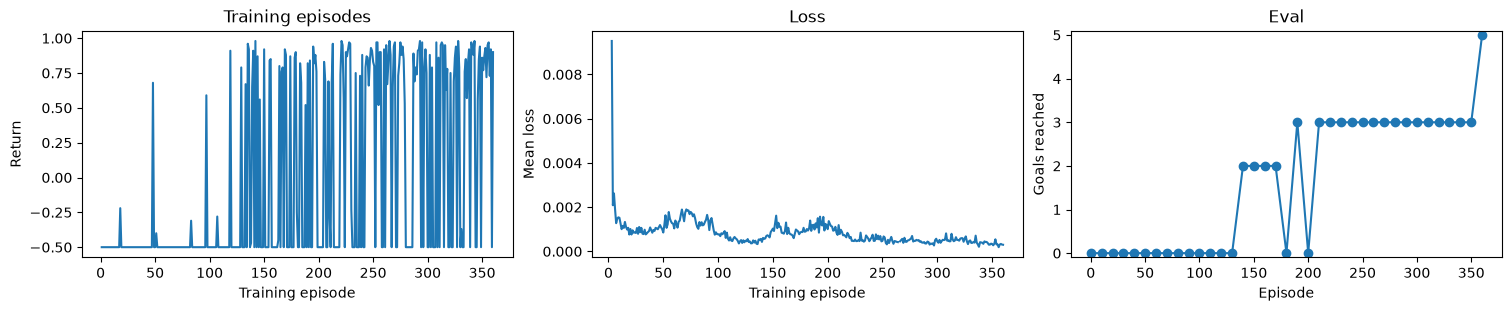

<HTML output, 10823 characters>

Training stopped after 360 episodes in 85.7s because every eval episode reached the goal


In [15]:
training_returns = []
training_losses = []
eval_rows = []
passed = False
started = perf_counter()
progress = display(HTML("Starting training…"), display_id=True)
curves = LearningCurves(baseline_successes, eval_episodes)
screen = Screen(title="Training episode (with exploration)")

for episode in range(1, training_episodes + 1):
    result = play_in_fresh_world(agent, learn=True, screen=screen)
    training_returns.append(result["return"])
    training_losses.append(result["loss"])
    if episode % eval_interval == 0 or episode == training_episodes:
        # the last check's episodes are the results below
        final_evaluations = evaluate(agent, capture=True)
        goals_reached = sum(check["success"] for check in final_evaluations)
        passed = goals_reached == eval_episodes
        eval_rows.append(
            {
                "After episode": episode,
                "Goals reached": goals_reached,
                "Mean steps": round(float(np.mean([check["steps"] for check in final_evaluations])), 1),
            }
        )
        curves.draw(training_returns, training_losses, eval_rows)
    progress.update(
        show_table(
            [
                {
                    "Training episode": f"{episode}/{training_episodes}",
                    "Transitions": agent.transitions,
                    "Gradient updates": agent.gradient_steps,
                    "Epsilon": round(agent.epsilon, 3),
                    "Episode loss": "no update" if np.isnan(result["loss"]) else round(result["loss"], 6),
                    "Eval success": f"{eval_rows[-1]['Goals reached']}/{eval_episodes}" if eval_rows else "not yet",
                }
            ]
        )
    )
    if passed:
        break

screen.draw()
reason = "every eval episode reached the goal" if passed else "it ran out of training episodes"
print(f"Training stopped after {episode} episodes in {perf_counter() - started:.1f}s because {reason}")

In [16]:
show_table(eval_rows)

10,0,50
20,0,50
30,0,50
40,0,50
50,0,50
60,0,50
70,0,50
80,0,50
90,0,50
100,0,50
110,0,50


## Evaluate

These are the eval episodes from the last check, which use greedy action selection, always taking the highest Q value with no exploring.

In [17]:
final_successes = sum(result["success"] for result in final_evaluations)
display(
    show_table(
        [
            {
                "Policy": "Untrained",
                "Training transitions": 0,
                "Goals reached": f"{baseline_successes}/{eval_episodes}",
            },
            {
                "Policy": "Trained",
                "Training transitions": agent.transitions,
                "Goals reached": f"{final_successes}/{eval_episodes}",
            },
        ]
    )
)

Untrained,0,0/5
Trained,13649,5/5


## Route

The route it took. Change `eval_episode_index` to look at another of the eval runs.

In [18]:
eval_episode_index = 0
selected_episode = final_evaluations[eval_episode_index]
route_rows = [
    {
        "Step": transition["step"],
        "From": transition["observation"]["room_name"],
        "Action": commands[transition["action"]],
        "To": transition["next_observation"].get("room_name", "episode ended"),
        "Reward": transition["reward"],
    }
    for transition in selected_episode["transitions"]
]
display(show_table(route_rows, mono_columns=("Action",)))

1,badly-paved road,move west,narrow road between lands,-0.01
2,narrow road between lands,move southwest,forest near mountains,-0.01
3,forest near mountains,move southwest,in front of hut,-0.01
4,in front of hut,move south,woodsman's hut,1


## Output

In [19]:
show_episode_transcript(selected_episode, title=f"Eval episode {eval_episode_index + 1} of {eval_episodes}")

<HTML output, 4778 characters>